In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2, poisson


In [50]:
df_counts = pd.read_csv('statistichebis.txt', header=None, names=['Conteggi'])

df_counts =: Crea una variabile chiamata df_counts in cui salviamo la tabella (DataFrame) creata da Pandas.
pd.read_csv(...): Chiama la funzione di Pandas che legge file di testo o CSV.
'statistichebis.txt': Il nome esatto del tuo file salvato sul computer.   
header=None: Dice a Pandas che il file non ha una riga d'intestazione con i nomi delle colonne nel testo originale.   names=['Conteggi']: Assegna manualmente il nome "Conteggi" all'unica colonna presente nel file.

In [51]:
conteggi = df_counts['Conteggi'].values

conteggi =: Crea una nuova variabile chiamata conteggi.

df_counts['Conteggi']: Estrae la colonna "Conteggi" dal DataFrame di Pandas.

.values: Converte la colonna da formato Pandas a un semplice vettore (array NumPy) di numeri puri, rendendo i calcoli matematici successivi più veloci.

In [52]:
N_tot = len(conteggi)
media = np.mean(conteggi)
varianza = np.var(conteggi, ddof=1) #ddof= Significa "Delta Degrees of Freedom = 1". Forza NumPy a dividere la somma degli scarti al quadrato per N-1 anziché per N, restituendo la varianza campionaria corretta (non distorta)
errore_media = np.std(conteggi, ddof=1) / np.sqrt(N_tot)
print(f"Media campionaria: {media:.4f} +/- {errore_media:.4f}")
print(f"Varianza campionaria: {varianza:.4f}")
rapporto = varianza/media
print(f"Rapporto Varianza/Media: {rapporto:.4f}")

Media campionaria: 1.5556 +/- 0.1727
Varianza campionaria: 1.6101
Rapporto Varianza/Media: 1.0350


In [53]:
valori_k, frequenze_osservate = np.unique(conteggi, return_counts=True)

valori_k, frequenze_osservate =: Assegna contemporaneamente due risultati a due variabili distinte.
np.unique(...): Trova i valori distinti presenti nel vettore conteggi e li ordina.
conteggi: Il vettore dei tuoi dati.
return_counts=True: Chiede a NumPy di contare quante volte appare ciascun valore.
valori_k: Diventerà il vettore dei conteggi unici (es. [0, 1, 2, 3, 4, 5]).
frequenze_osservate: Diventerà il vettore di quante volte si è verificato quel conteggio (es. quanti 0, quanti 1, ecc.).

In [54]:
def funzione_poisson(k, mu):
    return N_tot * poisson.pmf(k, mu)


Mu dal fit: 1.4888 +/- 0.1147
Chi2 / ndf: 3.52 / 4 = 0.88
p-value: 0.4743


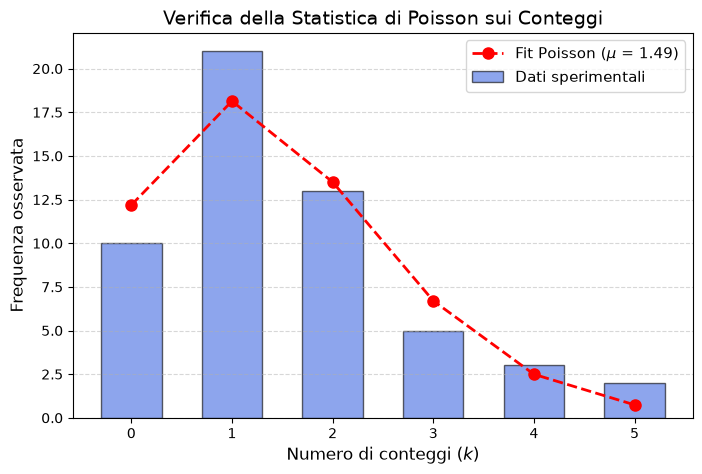

In [ ]:
# 1. Definiamo la funzione di probabilità di Poisson teorica riscalata al numero totale di eventi N_tot
def funzione_poisson(k, mu):
    # k: numero di conteggi (asse X)
    # mu: valore medio da stimare
    # poisson.pmf(k, mu): calcola la probabilità teorica di Poisson P(k; mu)
    # N_tot *: moltiplica la probabilità per il numero totale di intervalli per ottenere la frequenza attesa
    return N_tot * poisson.pmf(k, mu)


# 2. Eseguiamo il fit dei dati con la funzione di Poisson tramite minimi quadrati
# curve_fit: funzione di SciPy per fare il fit dei parametri
# funzione_poisson: la funzione modello da adattare ai dati
# valori_k: i dati dell'asse X (i conteggi unici 0, 1, 2, 3...)
# frequenze_osservate: i dati dell'asse Y (quante volte abbiamo osservato ciascun k)
# p0=[media]: stima iniziale del parametro mu per l'algoritmo di fit
# popt: vettore contenente i parametri ottimali calcolati dal fit (nel nostro caso contiene mu)
# pcov: matrice di covarianza contenente gli errori/varianze dei parametri
popt, pcov = curve_fit(
    funzione_poisson, valori_k, frequenze_osservate, p0=[media]
)


# 3. Estraiamo il valore di mu stimato dal fit (è il primo elemento dell'array popt)
mu_fit = popt[0]


# 4. Calcoliamo l'errore (deviazione standard) di mu_fit prendendo la radice quadrata del primo elemento della diagonale di pcov
sigma_mu_fit = np.sqrt(pcov[0][0])


# 5. Valutiamo le frequenze teoriche attese calcolando la funzione di Poisson per ciascun k usando il mu_fit ottenuto
frequenze_attese = funzione_poisson(valori_k, mu_fit)


# 6. Calcoliamo il valore statistico del Chi-Quadro (chi2_stat) con la formula sum( (osservati - attesi)^2 / attesi )
chi2_stat = np.sum(
    ((frequenze_osservate - frequenze_attese) ** 2) / frequenze_attese
)


# 7. Calcoliamo i gradi di libertà (ndf = number of degrees of freedom)
# len(valori_k): numero di bin (punti) considerati
# - 2: sottraiamo 1 vincolo per la norma totale (N_tot) e 1 vincolo per il parametro mu stimato dal fit
ndf = len(valori_k) - 2


# 8. Calcoliamo il p-value della prova d'ipotesi
# chi2.cdf(chi2_stat, ndf): calcola la probabilità cumulativa fino al valore chi2_stat
# 1 - ...: calcola l'area nella coda destra per verificare la bontà del fit (p-value > 0.05 indica un fit valido)
#p_value = 1 - chi2.cdf(chi2_stat, ndf)
# Fa esattamente la stessa identica cosa:
p_value = chi2.sf(chi2_calc, ndf)

# 9. Stampiamo a schermo il valore di mu estratto dal fit e la sua incertezza associata con 4 cifre decimali
print(f"Mu dal fit: {mu_fit:.4f} +/- {sigma_mu_fit:.4f}")


# 10. Stampiamo a schermo il Chi-Quadro calcolato, i gradi di libertà e il Chi-Quadro ridotto (chi2 / ndf)
print(f"Chi2 / ndf: {chi2_stat:.2f} / {ndf} = {chi2_stat/ndf:.2f}")


# 11. Stampiamo a schermo il p-value risultante formattato a 4 decimali
print(f"p-value: {p_value:.4f}")


# 12. Creiamo ed inizializziamo la figura del grafico con dimensioni 8x5 pollici
plt.figure(figsize=(8, 5))


# 13. Tracciamo l'istogramma a barre per i dati sperimentali osservati
# valori_k: posizioni delle barre su X
# frequenze_osservate: altezze delle barre su Y
# width=0.6: larghezza delle barre
# alpha=0.6: trasparenza al 60%
# color='royalblue': colore interno blu
# edgecolor='black': bordo nero
# label: testo da visualizzare nella legenda
plt.bar(
    valori_k,
    frequenze_osservate,
    width=0.6,
    alpha=0.6,
    color="royalblue",
    edgecolor="black",
    label="Dati sperimentali",
)


# 14. Sovrapponiamo i punti del fit di Poisson uniti da una linea tratteggiata
# 'ro--': marcatori circolari 'o' rossi 'r' uniti da linea tratteggiata '--'
# linewidth=2: spessore della linea
# markersize=8: dimensione dei pallini rossi
# label: testo della legenda con il valore mu formattato a 2 cifre decimali
plt.plot(
    valori_k,
    frequenze_attese,
    "ro--",
    linewidth=2,
    markersize=8,
    label=rf"Fit Poisson ($\mu$ = {mu_fit:.2f})",
)


# 15. Aggiungiamo l'etichetta dell'asse X con notazione LaTeX per il carattere k
plt.xlabel("Numero di conteggi ($k$)", fontsize=12)


# 16. Aggiungiamo l'etichetta dell'asse Y
plt.ylabel("Frequenza osservata", fontsize=12)


# 17. Impostiamo il titolo del grafico
plt.title("Verifica della Statistica di Poisson sui Conteggi", fontsize=14)


# 18. Fissiamo i tick dell'asse X nei soli valori interi presenti in valori_k
plt.xticks(valori_k)


# 19. Aggiungiamo una griglia orizzontale di supporto visivo leggermente trasparente
plt.grid(axis="y", linestyle="--", alpha=0.5)


# 20. Inseriamo la legenda nel grafico con font di dimensione 11
plt.legend(fontsize=11)


# 21. Mostriamo a schermo il grafico generato all'interno del Jupyter Notebook
plt.show()

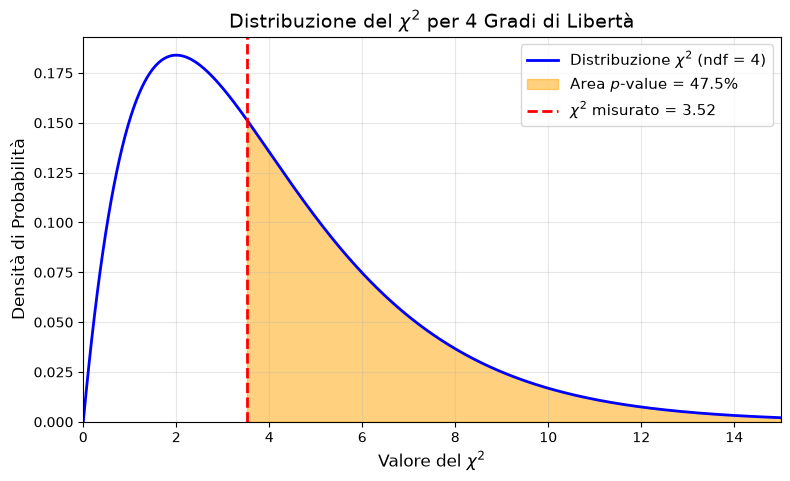

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# 1. Dati del tuo esperimento
chi2_calc = 3.52
ndf = 4
p_value = chi2.sf(chi2_calc, ndf)

# 2. Creiamo i punti per l'asse X
x = np.linspace(0, 15, 500)
y = chi2.pdf(x, ndf)

# 3. Creazione del grafico
plt.figure(figsize=(9, 5))

# Disegniamo la curva (uso 'rf' per evitare il warning su \chi)
plt.plot(x, y, 'b-', lw=2, label=rf'Distribuzione $\chi^2$ (ndf = {ndf})')

# Evidenziamo l'area del p-value
x_pvalue = np.linspace(chi2_calc, 15, 200)
y_pvalue = chi2.pdf(x_pvalue, ndf)
plt.fill_between(x_pvalue, y_pvalue, color='orange', alpha=0.5, 
                 label=f'Area $p$-value = {p_value*100:.1f}%')

# Tracciamo la linea verticale
plt.axvline(chi2_calc, color='red', linestyle='--', linewidth=2, 
            label=rf'$\chi^2$ misurato = {chi2_calc:.2f}')

# Personalizzazione
plt.title(rf'Distribuzione del $\chi^2$ per {ndf} Gradi di Libertà', fontsize=14)
plt.xlabel(r'Valore del $\chi^2$', fontsize=12)
plt.ylabel('Densità di Probabilità', fontsize=12)
plt.xlim(0, 15)
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)

plt.show()